This code for custom binning is partially based on the instruction provided by 10x genomics: https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd

Note, that the cell segmentation is performed using the python script NucleiSegmentation.py


In [1]:
import anndata
import gc
import geopandas as gpd
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import pickle
import scanpy as sc
import squidpy as sq

from csbdeep.utils import normalize
from matplotlib.colors import ListedColormap
from scipy import sparse
from shapely.geometry import Polygon, Point
from stardist.models import StarDist2D
from tifffile import imread, imwrite

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
2026-08-09 16:52:58.270722: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-09 16:52:58.291439: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorF

# Helper Functions and Variables
We define functions to help with plotting results in the next code block.

In [2]:
# Variables (names)
sample = "CRC_P6_5mm"  # Adapt to requirements
bin_size = "002um"
dir_cellseg = "cell_seg_stardist" # chosen cell segmentation method
f_wsi = 'Visium_HD_Human_Colon_Cancer_P2_tissue_image.btf'  # Adjust filename as needed

# Directories
basedir = Path("../../data")
dir_base_input = basedir / sample / "input" 
dir_base_output = basedir / sample / f"output/binned_outputs/square_{bin_size}"
dir_result_output = basedir / sample / "01_preprocessing" / dir_cellseg / bin_size
dir_custom_binning = dir_result_output / "custom_binning"
dir_result_output.mkdir(parents=True, exist_ok=True)
dir_custom_binning.mkdir(parents=True, exist_ok=True)

In [3]:
# General image plotting functions
def plot_mask_and_save_image(title, gdf, img, cmap, output_name=None, bbox=None):
    if bbox is not None:
        # Crop the image to the bounding box
        cropped_img = img[bbox[1]:bbox[3], bbox[0]:bbox[2]]
    else:
        cropped_img = img

    # Plot options
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Plot the cropped image
    axes[0].imshow(cropped_img, cmap='gray', origin='lower')
    axes[0].set_title(title)
    axes[0].axis('off')

    # Create filtering polygon
    if bbox is not None:
        bbox_polygon = Polygon([(bbox[0], bbox[1]), (bbox[2], bbox[1]), (bbox[2], bbox[3]), (bbox[0], bbox[3])])
        # Filter for polygons in the box
        intersects_bbox = gdf['geometry'].intersects(bbox_polygon)
        filtered_gdf = gdf[intersects_bbox]
    else:
        filtered_gdf=gdf

    # Plot the filtered polygons on the second axis
    filtered_gdf.plot(cmap=cmap, ax=axes[1])
    axes[1].axis('off')
    axes[1].legend(loc='upper left', bbox_to_anchor=(1.05, 1))


    # Save the plot if output_name is provided
    if output_name is not None:
        plt.savefig(output_name, bbox_inches='tight')  # Use bbox_inches='tight' to include the legend
    else:
        plt.show()

def plot_gene_and_save_image(title, gdf, gene, img, adata, bbox=None, output_name=None):

    if bbox is not None:
        # Crop the image to the bounding box
        cropped_img = img[bbox[1]:bbox[3], bbox[0]:bbox[2]]
    else:
        cropped_img = img

    # Plot options
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Plot the cropped image
    axes[0].imshow(cropped_img, cmap='gray', origin='lower')
    axes[0].set_title(title)
    axes[0].axis('off')

    # Create filtering polygon
    if bbox is not None:
        bbox_polygon = Polygon([(bbox[0], bbox[1]), (bbox[2], bbox[1]), (bbox[2], bbox[3]), (bbox[0], bbox[3])])


    # Find a gene of interest and merge with the geodataframe
    gene_expression = adata[:, gene].to_df()
    gene_expression['id'] = gene_expression.index
    merged_gdf = gdf.merge(gene_expression, left_on='id', right_on='id')

    if bbox is not None:
        # Filter for polygons in the box
        intersects_bbox = merged_gdf['geometry'].intersects(bbox_polygon)
        filtered_gdf = merged_gdf[intersects_bbox]
    else:
        filtered_gdf = merged_gdf

    # Plot the filtered polygons on the second axis
    filtered_gdf.plot(column=gene, cmap='inferno', legend=True, ax=axes[1])
    axes[1].set_title(gene)
    axes[1].axis('off')
    axes[1].legend(loc='upper left', bbox_to_anchor=(1.05, 1))

    # Save the plot if output_name is provided
    if output_name is not None:
        plt.savefig(output_name, bbox_inches='tight')  # Use bbox_inches='tight' to include the legend
    else:
        plt.show()

def plot_clusters_and_save_image(title, gdf, img, adata, bbox=None, color_by_obs=None, output_name=None, color_list=None):
    color_list=["#7f0000","#808000","#483d8b","#008000","#bc8f8f","#008b8b","#4682b4","#000080","#d2691e","#9acd32","#8fbc8f","#800080","#b03060","#ff4500","#ffa500","#ffff00","#00ff00","#8a2be2","#00ff7f","#dc143c","#00ffff","#0000ff","#ff00ff","#1e90ff","#f0e68c","#90ee90","#add8e6","#ff1493","#7b68ee","#ee82ee"]
    if bbox is not None:
        cropped_img = img[bbox[1]:bbox[3], bbox[0]:bbox[2]]
    else:
        cropped_img = img

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(cropped_img, cmap='gray', origin='lower')
    axes[0].set_title(title)
    axes[0].axis('off')

    if bbox is not None:
        bbox_polygon = Polygon([(bbox[0], bbox[1]), (bbox[2], bbox[1]), (bbox[2], bbox[3]), (bbox[0], bbox[3])])

    unique_values = adata.obs[color_by_obs].astype('category').cat.categories
    num_categories = len(unique_values)

    if color_list is not None and len(color_list) >= num_categories:
        custom_cmap = ListedColormap(color_list[:num_categories], name='custom_cmap')
    else:
        # Use default tab20 colors if color_list is insufficient
        tab20_colors = plt.cm.tab20.colors[:num_categories]
        custom_cmap = ListedColormap(tab20_colors, name='custom_tab20_cmap')

    merged_gdf = gdf.merge(adata.obs[color_by_obs].astype('category'), left_on='id', right_index=True)

    if bbox is not None:
        intersects_bbox = merged_gdf['geometry'].intersects(bbox_polygon)
        filtered_gdf = merged_gdf[intersects_bbox]
    else:
        filtered_gdf = merged_gdf

    # Plot the filtered polygons on the second axis
    plot = filtered_gdf.plot(column=color_by_obs, cmap=custom_cmap, ax=axes[1], legend=True)
    axes[1].set_title(color_by_obs)
    legend = axes[1].get_legend()
    legend.set_bbox_to_anchor((1.05, 1))
    axes[1].axis('off')

    # Move legend outside the plot
    plot.get_legend().set_bbox_to_anchor((1.25, 1))

    if output_name is not None:
        plt.savefig(output_name, bbox_inches='tight')
    else:
        plt.show()

# Plotting function for nuclei area distribution
def plot_nuclei_area(gdf,area_cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(15, 4))
    # Plot the histograms
    axs[0].hist(gdf['area'], bins=50, edgecolor='black')
    axs[0].set_title('Nuclei Area')

    axs[1].hist(gdf[gdf['area'] < area_cut_off]['area'], bins=50, edgecolor='black')
    axs[1].set_title('Nuclei Area Filtered:'+str(area_cut_off))

    plt.tight_layout()
    plt.show()

# Total UMI distribution plotting function
def total_umi(adata_, cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    # Box plot
    axs[0].boxplot(adata_.obs["total_counts"], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[0].set_title('Total Counts')

    # Box plot after filtering
    axs[1].boxplot(adata_.obs["total_counts"][adata_.obs["total_counts"] > cut_off], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[1].set_title('Total Counts > ' + str(cut_off))

    # Remove y-axis ticks and labels
    for ax in axs:
        ax.get_yaxis().set_visible(False)

    plt.tight_layout()
    plt.show()


**Note**
Only run the next cell if you want to process the entire high res image. Note that this requires a lot of RAM. 
In the cell after this, you should then uncomment the last line:
`#plot_mask_and_save_image(title="Region of Interest 1",...,output_name=dir_base+"image_mask.ROI1.tif")
`

In [4]:
'''
# Load the image file
# Change dir_base as needed to the directory where the downloaded example data is stored
img = imread(dir_base_input + f_wsi)

# Load the pretrained model
# model = StarDist2D.from_pretrained('2D_versatile_he')

# Percentile normalization of the image
# Adjust min_percentile and max_percentile as needed
min_percentile = 5
max_percentile = 95
img = normalize(img, min_percentile, max_percentile)
'''

"\n# Load the image file\n# Change dir_base as needed to the directory where the downloaded example data is stored\nimg = imread(dir_base_input + f_wsi)\n\n# Load the pretrained model\n# model = StarDist2D.from_pretrained('2D_versatile_he')\n\n# Percentile normalization of the image\n# Adjust min_percentile and max_percentile as needed\nmin_percentile = 5\nmax_percentile = 95\nimg = normalize(img, min_percentile, max_percentile)\n"

The following code plots a region of interest from the polygons. 
We can extract the min and max positions from the tissue positions.
In the provided code, the bounding box argument (bbox) is entered as <code>(x min, y min, x max, y max)</code>.

In [5]:
# Plot the nucleus segmentation
# bbox=(x min,y min,x max,y max)
tissue_path = dir_base_output / "spatial/tissue_positions.parquet" # stores ID for each bin, bin coordinates in pixel and array format
tissuepositions = pd.read_parquet(tissue_path)
col = "pxl_col_in_fullres"
row = "pxl_row_in_fullres"
x_min = math.floor(tissuepositions.loc[tissuepositions[col] > 0, col].min())
x_max = math.ceil(tissuepositions.loc[tissuepositions[col] > 0, col].max())
y_min = math.floor(tissuepositions.loc[tissuepositions[row] > 0, row].min())
y_max = math.ceil(tissuepositions.loc[tissuepositions[row] > 0, row].max())
#tissuepositions.close()

# Load the saved polys dictionary
with open((dir_result_output / "polys_FullSection.pckl"), "rb") as f:
    polys = pickle.load(f)

# Reconstruct the geometries from the coordinate data
geometries = []
for nuclei in range(len(polys['coord'])):
    coords = [(y, x) for x, y in zip(polys['coord'][nuclei][0], polys['coord'][nuclei][1])]
    geometries.append(Polygon(coords))

# Create the GeoDataFrame
gdf = gpd.GeoDataFrame(geometry=geometries)
gdf["id"] = [f"ID_{i+1}" for i in range(len(gdf))]

# Now gdf is ready to use again
print(gdf.head())

# Define a single color cmap
cmap=ListedColormap(['grey'])

# Create Plot
#plot_mask_and_save_image(title="Region of Interest 1",gdf=gdf,bbox=(x_min,x_max,y_min,y_max),cmap=cmap,img=img,output_name=dir_base+"image_mask.ROI1.tif")

# RAM saver
del tissuepositions, polys, geometries
gc.collect()

                                            geometry    id
0  POLYGON ((2462.755 3658.000, 2462.680 3658.931...  ID_1
1  POLYGON ((2267.931 3902.000, 2267.278 3903.050...  ID_2
2  POLYGON ((2325.759 3870.000, 2323.000 3872.984...  ID_3
3  POLYGON ((2019.944 3888.000, 2019.802 3888.756...  ID_4
4  POLYGON ((2338.063 3854.000, 2337.283 3855.449...  ID_5


0

Note: the min and max coordinates are correct. However, the region of interest is still smaller in this specific plot than it actually is (does not align with the min and max values).
Possible explanations: 
1. ROI is cropped due to oversize
2. pixel values are incorret somewhere in the translation to the plot. Either in the image itself or in the calculation?

# Binning Visium HD Gene Expression Data
In the following code block, we load the 2x2 µm Visium HD gene expression data and tissue position information. 
A GeoDataframe is then created. 
Be sure that the expression data and tissue position files are in the same directory as the high-resolution H&E microscope image.

In [6]:
# memory saving version
import gc
from pathlib import Path
import pandas as pd
import geopandas as gpd
import scanpy as sc

# 1. Read AnnData
f_raw_h5 = dir_base_output / 'filtered_feature_bc_matrix.h5'
adata = sc.read_10x_h5(f_raw_h5)

# 2. Load ONLY necessary columns from Parquet
tissue_position_file = dir_base_output / 'spatial/tissue_positions.parquet'
cols_to_load = ['barcode', 'pxl_row_in_fullres', 'pxl_col_in_fullres', 'in_tissue']

# Load parquet with explicit index
df_tissue_positions = pd.read_parquet(
    tissue_position_file, 
    columns=[c for c in cols_to_load if c != 'barcode']  # Handles barcode as index or column
)

if 'barcode' in df_tissue_positions.columns:
    df_tissue_positions = df_tissue_positions.set_index('barcode')

# 3. Join directly on index in-place (avoiding pd.merge copies)
adata.obs = adata.obs.join(df_tissue_positions, how='left')
adata.obs['pxl_row_in_fullres'] = adata.obs['pxl_row_in_fullres'].astype('float32')
adata.obs['pxl_col_in_fullres'] = adata.obs['pxl_col_in_fullres'].astype('float32')

# 4. Save spatial coordinates to obsm for standard Scanpy compatibility
spatial_cols = ['pxl_row_in_fullres', 'pxl_col_in_fullres']
adata.obsm['spatial'] = adata.obs[spatial_cols].to_numpy()

print("creating gdf")
# 5. Create GeoDataFrame using VECTORIZED points_from_xy
# (Only create if you strictly need a GeoDataFrame for spatial querying)
gdf_coordinates = gpd.GeoDataFrame(
    adata.obs[spatial_cols],  # Slice only coordinates to keep gdf lightweight
    geometry=gpd.points_from_xy(
        adata.obs['pxl_col_in_fullres'], 
        adata.obs['pxl_row_in_fullres']
    ),
    crs=None
)

# Clean up temporary reference
del df_tissue_positions
gc.collect()

anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


creating gdf


0

In [7]:
# Load Visium HD data
f_raw_h5 = dir_base_output / 'filtered_feature_bc_matrix.h5'
adata = sc.read_10x_h5(f_raw_h5)

# Load the Spatial Coordinates
tissue_position_file = dir_base_output / 'spatial/tissue_positions.parquet'
df_tissue_positions=pd.read_parquet(tissue_position_file)

#Set the index of the dataframe to the barcodes
df_tissue_positions = df_tissue_positions.set_index('barcode')

# Create an index in the dataframe to check joins
df_tissue_positions['index']=df_tissue_positions.index

# Adding the tissue positions to the meta data
adata.obs = pd.merge(adata.obs, df_tissue_positions, left_index=True, right_index=True)

# Create a GeoDataFrame from the DataFrame of coordinates
geometry = [Point(xy) for xy in zip(df_tissue_positions['pxl_col_in_fullres'], df_tissue_positions['pxl_row_in_fullres'])]
gdf_coordinates = gpd.GeoDataFrame(df_tissue_positions, geometry=geometry)

del f_raw_h5, df_tissue_positions
gc.collect()

anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


0

We next check each barcode to determine if they are in a cell nucleus. 
There is a chance that two or more cell nuclei can overlap, so to remove barcode assignment ambiguity, we will later filter to retain only barcodes that are uniquely assigned.

**Structure of the resulting AnnData Object**  
Store everything in an Anndata object file `Filtered_custom_bins.h5ad`, which contains:    
     AnnData object with n_obs × n_vars = n_bins × embeddings (size of embedding dimension)  
      ├── `.X`               → oberservations (bins) x vars (variables, i.e genes)  
      ├── `.obs`             → in_tissue (is the bin tissue or empty), array_row, array_col, pxl_row..., pxl_col..., index_x (bin_id), index_y (bin_id), id (nucleus_id)  
      ├── `.obsm["spatial"]` → currently empty  
      └── `.uns`             → currently empty  

In [8]:
# 1. Spatial join (preserves barcode index on result_spatial_join)
result_spatial_join = gpd.sjoin(gdf_coordinates, gdf, how='left', predicate='within')

# 2. Check if point fell inside any polygon
result_spatial_join['is_within_polygon'] = ~result_spatial_join['index_right'].isna()

# 3. Find barcodes that matched MULTIPLE polygons (duplicated on the DataFrame index)
# index.duplicated() directly checks the barcode index without needing a column
overlapping_barcodes = result_spatial_join.index[result_spatial_join.index.duplicated()].unique()

# 4. Filter to points inside a polygon AND NOT in an overlapping region
valid_mask = (
    result_spatial_join['is_within_polygon'] & 
    ~result_spatial_join.index.isin(overlapping_barcodes)
)
barcodes_in_one_polygon = result_spatial_join[valid_mask]

# 5. Subset AnnData directly using index matching
filtered_adata = adata[adata.obs_names.isin(barcodes_in_one_polygon.index)].copy()

# 6. Join metadata safely using the barcode index
cols_to_add = ['id', 'is_within_polygon']
filtered_adata.obs = filtered_adata.obs.join(barcodes_in_one_polygon[cols_to_add], how='left')
filtered_adata.obs["Slide_ID"] = sample

# 7. Save to h5ad (no need to temporarily attach/detach geometry to .obs)
filtered_adata.write(dir_custom_binning / "filtered_custom_bins.h5ad")

anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [9]:
# RAM saver
del result_spatial_join, barcodes_in_one_polygon
gc.collect()

0

Just to check: since Nuclei should only be found within tissue, not outside, use this method to check if all the nuclei are within tissue (in_tissue == 0 should result in 0).

In [10]:
#adata = sc.read(f"output/{person}/{bin_size}/filtered_custom_bins.h5ad")
num_zero = (filtered_adata.obs["in_tissue"] == 1).sum()
print(f"Number of nuclei found in tissue: {num_zero}")

Number of nuclei found in tissue: 2344732


Next we perform a gene-wise count summation for the custom binned data. 
This step will take a few minutes to execute and can vary based on the number of nuclei in the image.

**Structure of the resulting `grouped_filtered_adata`**  
Store everything in an Anndata object file `nuclei_grouped_UMI_count.h5ad`, which contains:    
     AnnData object with n_obs × n_vars = nucleus IDs × embedding_dim  
      ├── `.X`               → *oberservations* (**rows** nucleus IDs) x *vars* (**column**: gene ID, **cell**: summed gene expression count (UMI count for this gene over all bins in this nucleus))     
      ├── `.obs`             → *id* (nucleus id), *Slide_ID*   
      ├── `.var`             → *gene_ids*, *feature_types* (usually "Gene Expression" in standard 10x datasets), *genome* (genome reference, e.g. GRCh38)   
      ├── `.obsm["spatial"]` → currently empty  
      └── `.uns`             → currently empty 


In [10]:
# Group the data by unique nucleous IDs
groupby_object = filtered_adata.obs.groupby(['id'], observed=True)

# Extract the gene expression counts from the AnnData object
counts = filtered_adata.X

# Obtain the number of unique nuclei and the number of genes in the expression data
N_groups = groupby_object.ngroups
N_genes = counts.shape[1]

# Initialize a sparse matrix to store the summed gene counts for each nucleus
summed_counts = sparse.lil_matrix((N_groups, N_genes))

# Lists to store the IDs of polygons and the current row index
polygon_id = []
row = 0

# Iterate over each unique polygon to calculate the sum of gene counts.
for polygons, idx_ in groupby_object.indices.items():
    summed_counts[row] = counts[idx_].sum(0)
    row += 1
    polygon_id.append(polygons)

# Create and AnnData object from the summed count matrix
summed_counts = summed_counts.tocsr()
obs_df = pd.DataFrame(polygon_id, columns=['id'], index=polygon_id)

# Merge with geometry from gdf
# Stores the geometry as pixels for each nucleus to be used for overlay for WSI patches
obs_df = obs_df.merge(gdf[['id', 'geometry']], on='id', how='left')

grouped_filtered_adata = anndata.AnnData(X=summed_counts, obs=obs_df, var=filtered_adata.var)
grouped_filtered_adata.obs["Slide_ID"] = sample


geodata = grouped_filtered_adata.obs["geometry"]
grouped_filtered_adata.obs = grouped_filtered_adata.obs.drop(columns=["geometry"])
grouped_filtered_adata.write(dir_custom_binning / "nuclei_grouped_UMI_count.h5ad")
grouped_filtered_adata.obs["geometry"] = geodata

aligned_df.py (67): Transforming to str index.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [11]:
# RAM saver
del groupby_object, N_groups, polygon_id, summed_counts, obs_df
gc.collect()

0

# Nuclei Binning Results
In this demonstration, we filter the results to remove very large nuclei, which could be improperly segmented nuclei aggregates or image artifacts, and remove nuclei with too few UMI counts to make cluster interpretation and visualization easier. 
This step is optional and performing it will likely depend on the sample.

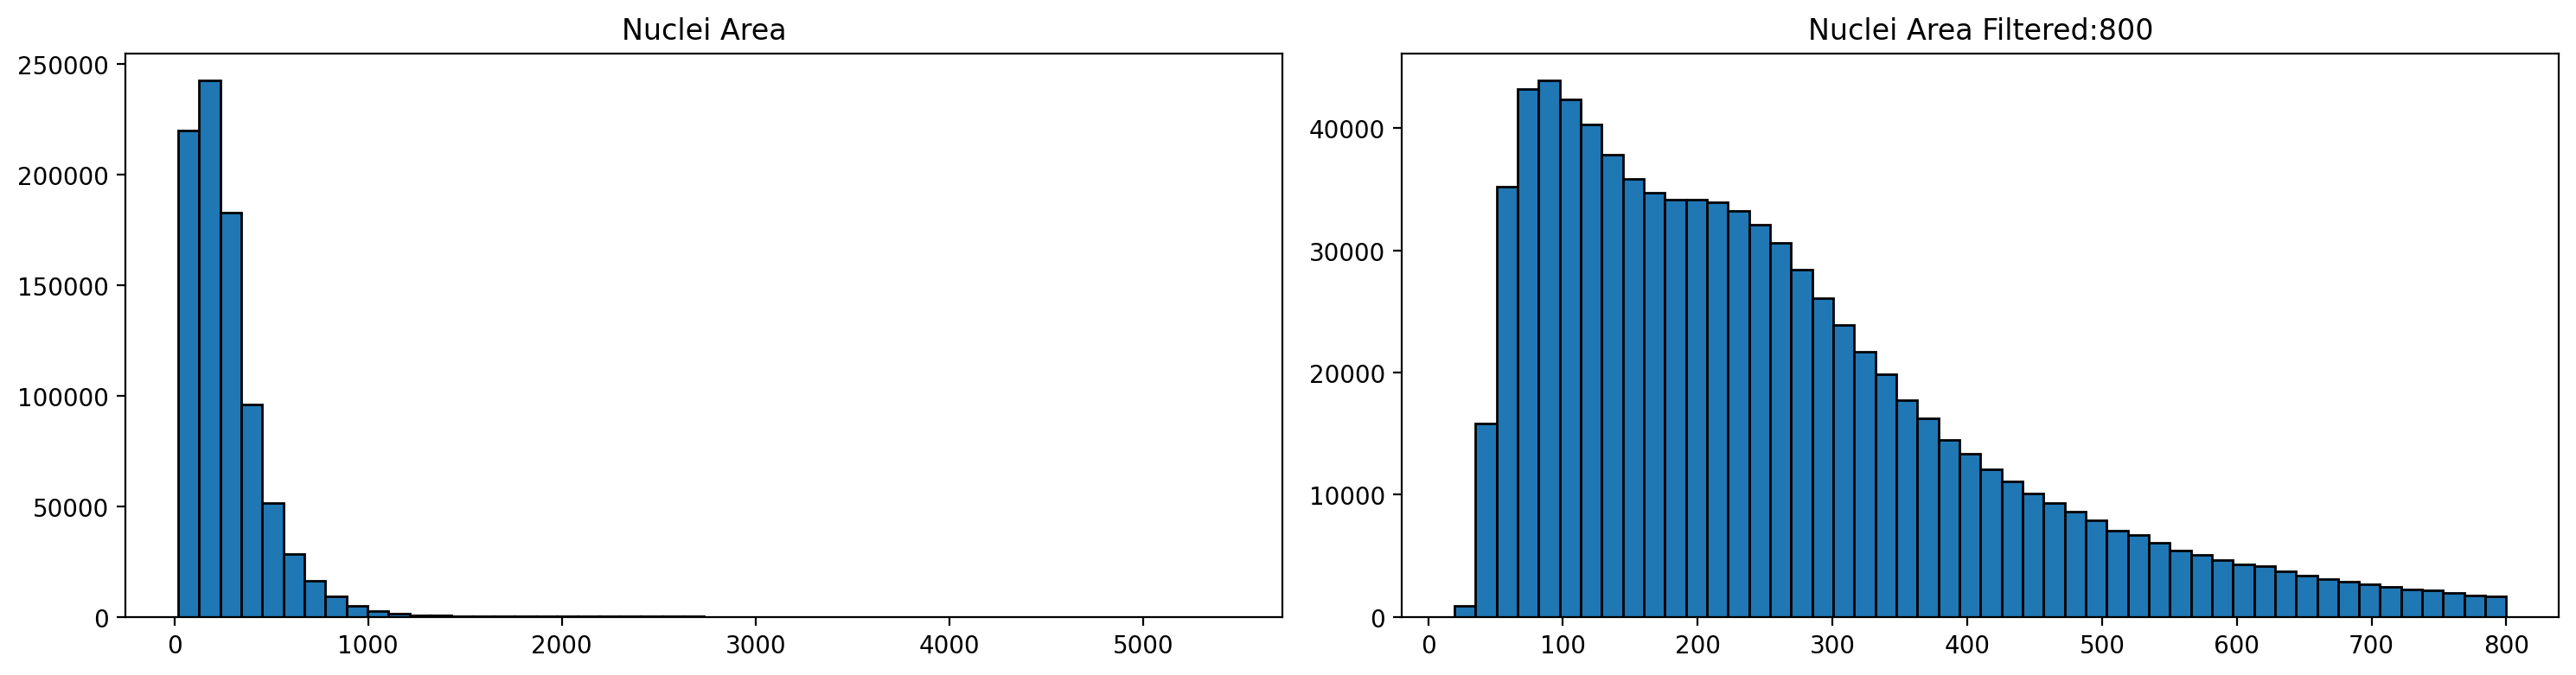

In [12]:
# Store the area of each nucleus in the GeoDataframe
gdf['area'] = gdf['geometry'].area

# Calculate quality control metrics for the original AnnData object
sc.pp.calculate_qc_metrics(grouped_filtered_adata, inplace=True)

# Plot the nuclei area distribution before and after filtering
plot_nuclei_area(gdf=gdf,area_cut_off=800)

x-axis: nucleus area  
y-axis: no. of nuclei with that area

Based on the nuclei distribution we selected a value of 1000 to filter the data.

Next we plot the total UMI distribution.

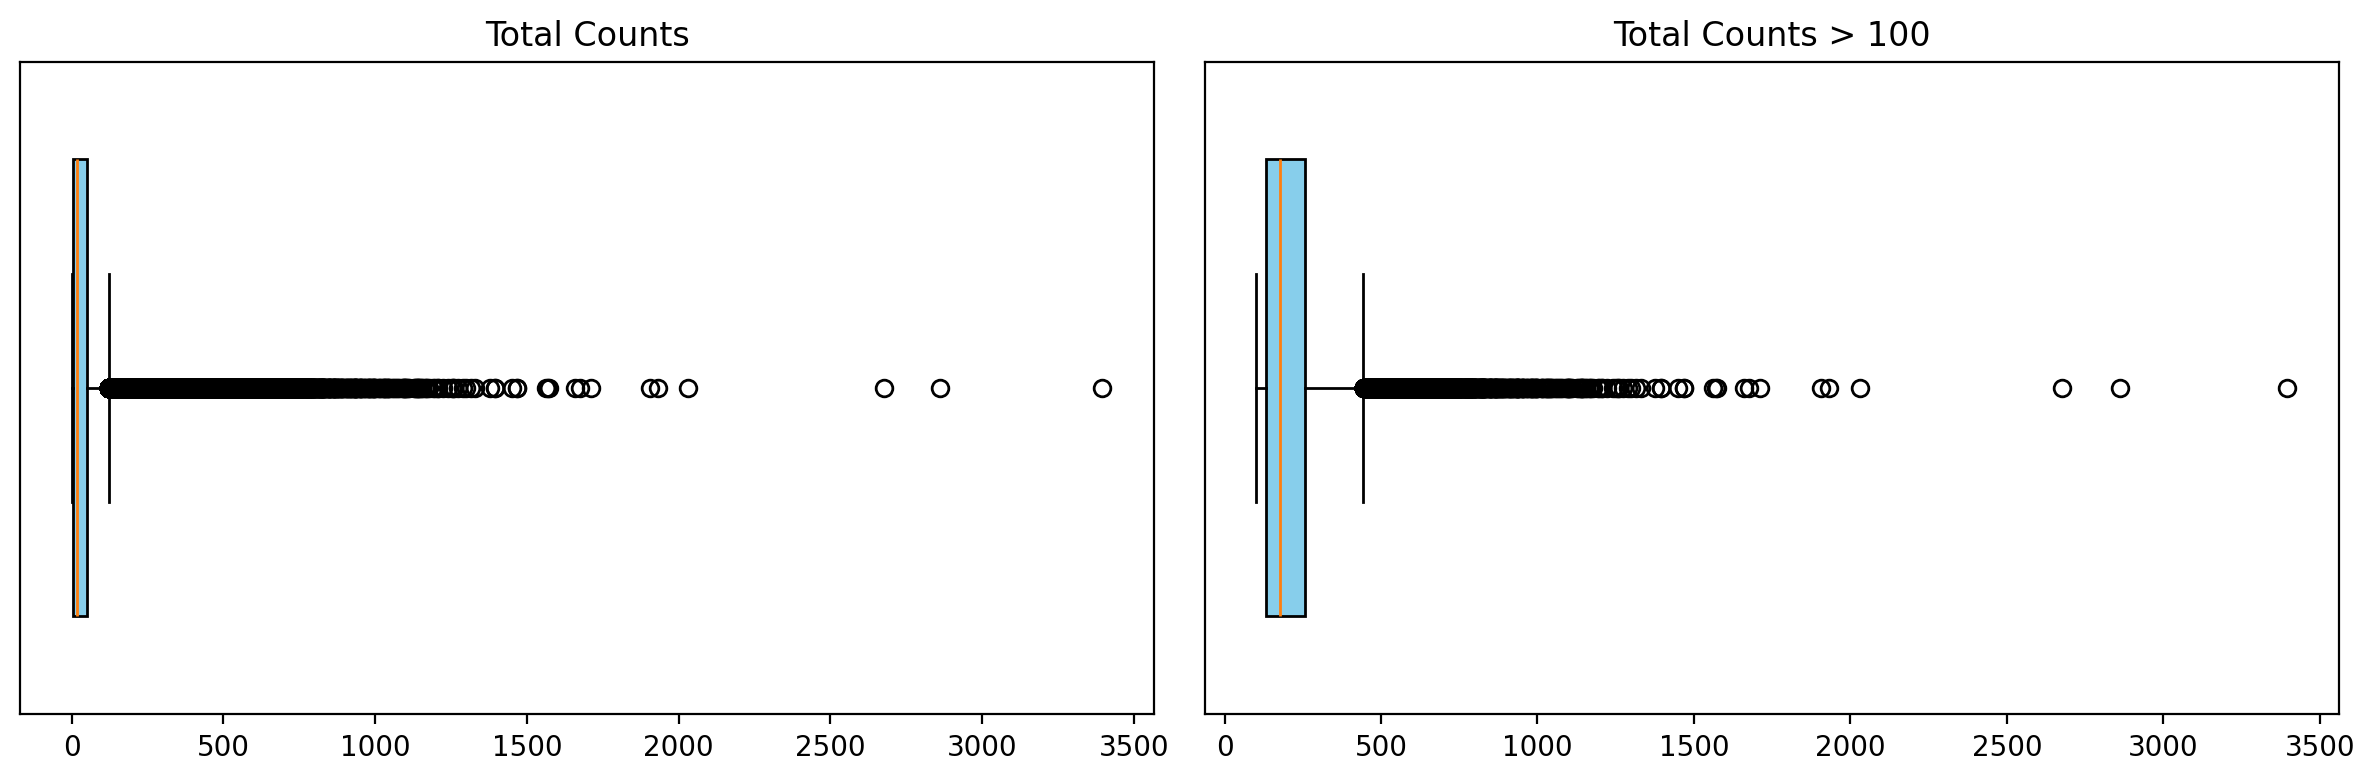

In [24]:
# Plot total UMI distribution
cutoff = 100
total_umi(grouped_filtered_adata, cutoff)

This cell computes both a knee-point cutoff (using the standard "elbow" method on the sorted UMI curve, the same logic used for scRNA-seq empty-droplet detection) and a MAD-based cutoff, then plots them next to the current hardcoded value from the previous step so you can compare.

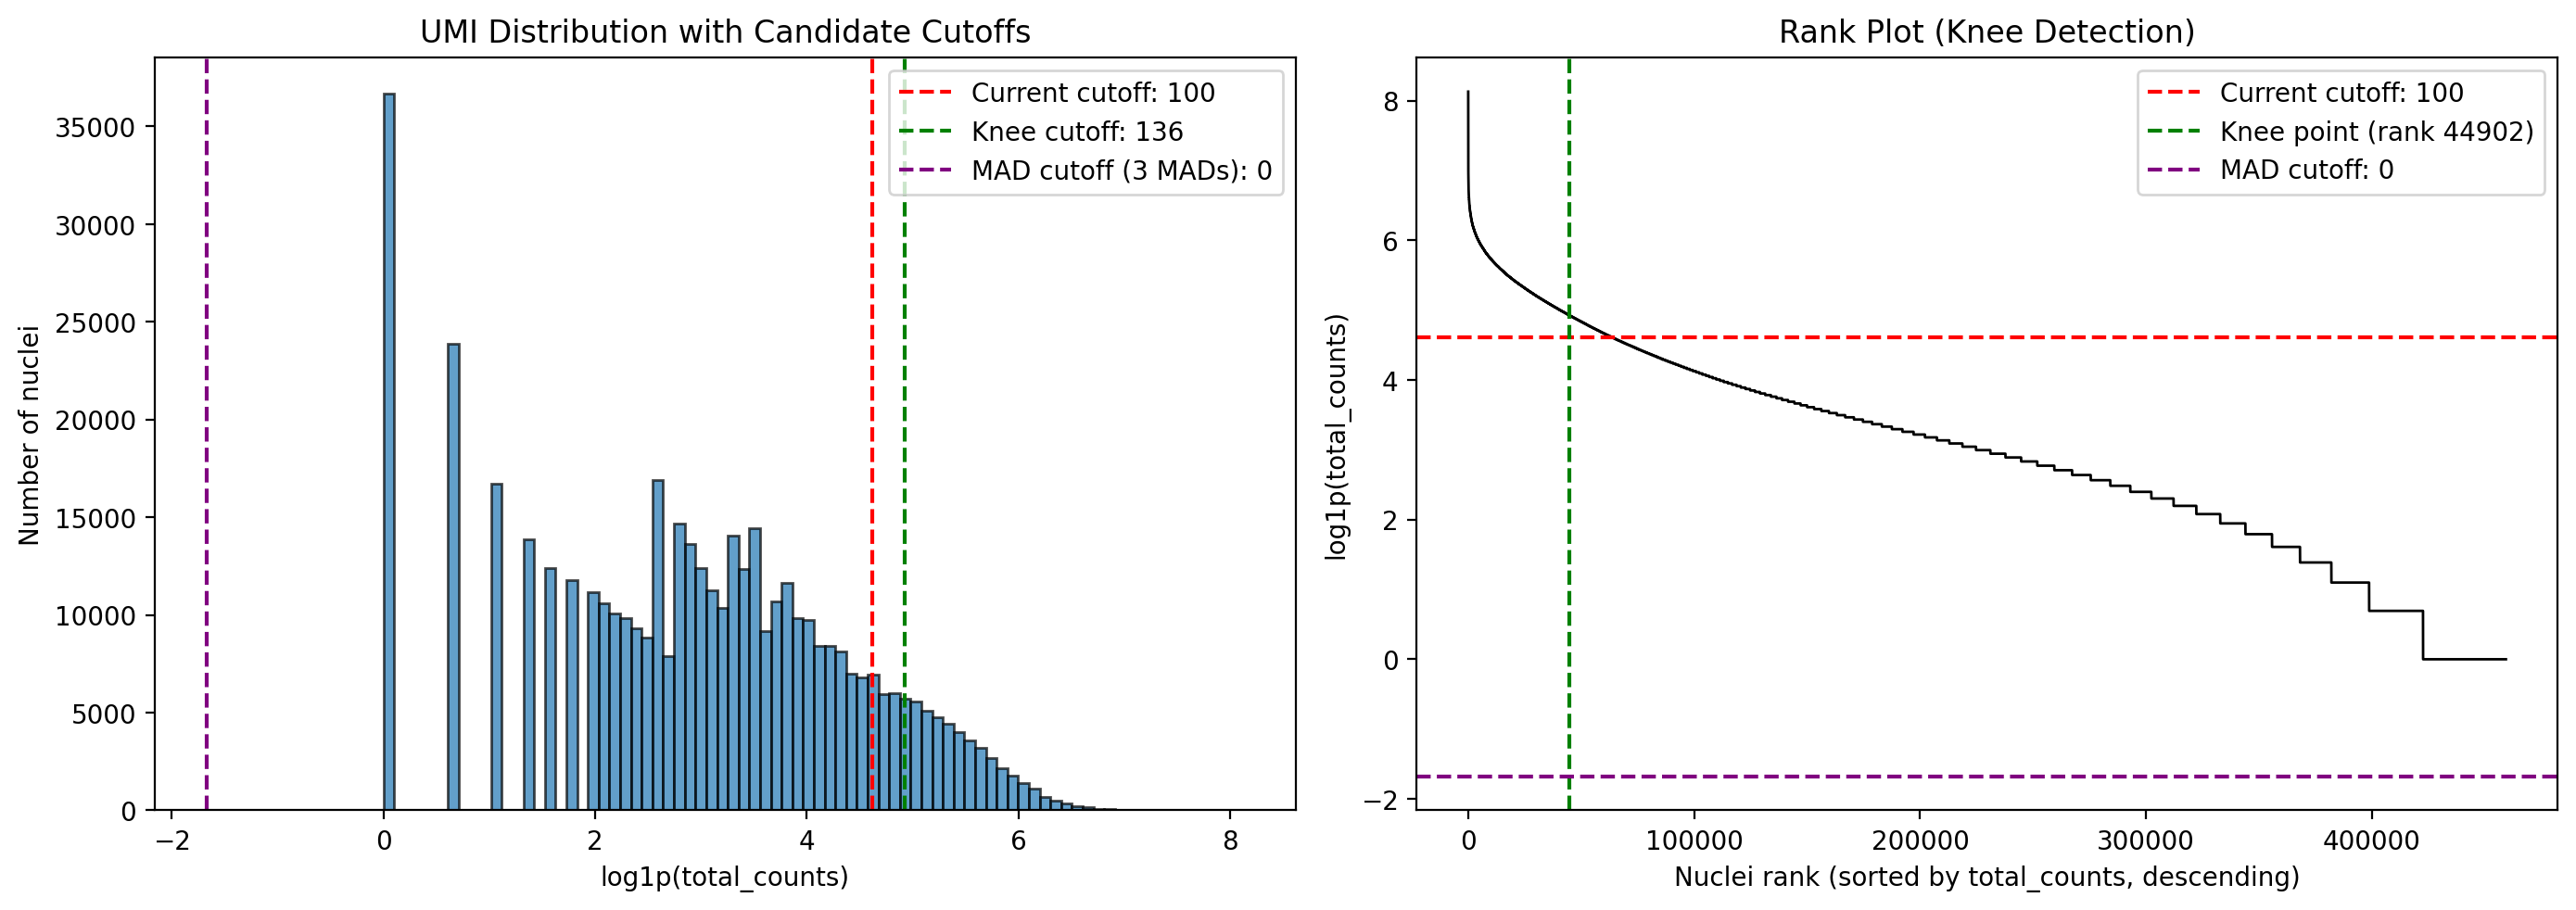

Total nuclei: 459257
  Pass current cutoff (>100):    63068 (13.7%)
  Pass knee cutoff (>136):       44902 (9.8%)
  Pass MAD cutoff (>0):         422557 (92.0%)


In [25]:
from scipy.stats import median_abs_deviation

def plot_umi_cutoff_diagnostics(adata_, current_cutoff=cutoff):
    counts = adata_.obs["total_counts"].values
    log_counts = np.log1p(counts)

    # --- 1. Knee/elbow point on the sorted UMI curve ---
    # Sort counts descending (like a "barcode rank plot")
    sorted_counts = np.sort(counts)[::-1]
    x = np.arange(len(sorted_counts))
    y = np.log1p(sorted_counts)

    # Normalize x and y to [0,1] so distances are comparable
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())

    # Knee = point with max distance from the straight line connecting
    # the first and last point of the curve
    line_vec = np.array([x_norm[-1] - x_norm[0], y_norm[-1] - y_norm[0]])
    line_vec_norm = line_vec / np.linalg.norm(line_vec)
    points = np.column_stack([x_norm - x_norm[0], y_norm - y_norm[0]])
    proj_lengths = points @ line_vec_norm
    proj_points = np.outer(proj_lengths, line_vec_norm)
    distances = np.linalg.norm(points - proj_points, axis=1)
    knee_idx = np.argmax(distances)
    knee_cutoff = sorted_counts[knee_idx]

    # --- 2. MAD-based cutoff (on log scale, lower tail) ---
    med = np.median(log_counts)
    mad = median_abs_deviation(log_counts, scale="normal")  # scale='normal' approximates std dev
    n_mads = 3
    mad_cutoff_log = med - n_mads * mad
    mad_cutoff = np.expm1(mad_cutoff_log)
    mad_cutoff = max(mad_cutoff, 0)  # UMI counts can't be negative

    # --- Plot ---
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    # Histogram with all three cutoffs
    axs[0].hist(log_counts, bins=80, edgecolor='black', alpha=0.7)
    axs[0].axvline(np.log1p(current_cutoff), color='red', linestyle='--', label=f'Current cutoff: {current_cutoff}')
    axs[0].axvline(np.log1p(knee_cutoff), color='green', linestyle='--', label=f'Knee cutoff: {knee_cutoff:.0f}')
    axs[0].axvline(mad_cutoff_log, color='purple', linestyle='--', label=f'MAD cutoff ({n_mads} MADs): {mad_cutoff:.0f}')
    axs[0].set_xlabel('log1p(total_counts)')
    axs[0].set_ylabel('Number of nuclei')
    axs[0].set_title('UMI Distribution with Candidate Cutoffs')
    axs[0].legend()

    # Rank plot (barcode-rank style) showing the knee visually
    axs[1].plot(x, y, color='black', linewidth=1)
    axs[1].axhline(np.log1p(current_cutoff), color='red', linestyle='--', label=f'Current cutoff: {current_cutoff}')
    axs[1].axvline(knee_idx, color='green', linestyle='--', label=f'Knee point (rank {knee_idx})')
    axs[1].axhline(mad_cutoff_log, color='purple', linestyle='--', label=f'MAD cutoff: {mad_cutoff:.0f}')
    axs[1].set_xlabel('Nuclei rank (sorted by total_counts, descending)')
    axs[1].set_ylabel('log1p(total_counts)')
    axs[1].set_title('Rank Plot (Knee Detection)')
    axs[1].legend()

    plt.tight_layout()
    plt.show()

    # Print summary
    n_total = len(counts)
    print(f"Total nuclei: {n_total}")
    print(f"  Pass current cutoff (>{current_cutoff}):    {(counts > current_cutoff).sum()} ({(counts > current_cutoff).mean():.1%})")
    print(f"  Pass knee cutoff (>{knee_cutoff:.0f}):       {(counts > knee_cutoff).sum()} ({(counts > knee_cutoff).mean():.1%})")
    print(f"  Pass MAD cutoff (>{mad_cutoff:.0f}):         {(counts > mad_cutoff).sum()} ({(counts > mad_cutoff).mean():.1%})")

    return knee_cutoff, mad_cutoff

knee_cutoff, mad_cutoff = plot_umi_cutoff_diagnostics(grouped_filtered_adata, current_cutoff=cutoff)

For this dataset, a total UMI cutoff of 100 was used. These values (nuclei area and UMI cutoff) may need adjustment for other datasets. 
Selecting appropriate cutoff values might require iteration based on the intepretation of the clustering results.

The following code block filters the data.

In [27]:
# Total nuclei before filtering
n_total = grouped_filtered_adata.n_obs

# Create individual masks
mask_area = grouped_filtered_adata.obs['id'].isin(gdf[gdf['area'] < 500].id)
mask_count = grouped_filtered_adata.obs['total_counts'] > 50

# How many pass / fail each filter on its own
n_pass_area = mask_area.sum()
n_pass_count = mask_count.sum()
n_fail_area = (~mask_area).sum()
n_fail_count = (~mask_count).sum()

# Combined filter (what actually gets applied)
mask_both = mask_area & mask_count
n_pass_both = mask_both.sum()

# Breakdown of *why* each removed nucleus was removed
removed_area_only   = (~mask_area &  mask_count).sum()  # too large, but UMI was fine
removed_count_only  = ( mask_area & ~mask_count).sum()  # UMI too low, but area was fine
removed_both        = (~mask_area & ~mask_count).sum()  # too large AND UMI too low

print(f"Total nuclei before filtering: {n_total}")
print(f"  Removed for area >= 500 (large/aggregated nuclei): {n_fail_area} ({n_fail_area/n_total:.1%})")
print(f"  Removed for total_counts <= 100 (low UMI):          {n_fail_count} ({n_fail_count/n_total:.1%})")
print()
print(f"  Removed by area filter ONLY:        {removed_area_only}")
print(f"  Removed by UMI filter ONLY:         {removed_count_only}")
print(f"  Removed by BOTH filters:            {removed_both}")
print()
print(f"Nuclei remaining after both filters: {n_pass_both} ({n_pass_both/n_total:.1%})")

# Apply both masks to the original AnnData to create a new filtered AnnData object
count_area_filtered_adata = grouped_filtered_adata[mask_area & mask_count, :]
count_area_filtered_adata.var_names_make_unique()

# Calculate quality control metrics for the filtered AnnData object
sc.pp.calculate_qc_metrics(count_area_filtered_adata, inplace=True)

Total nuclei before filtering: 459257
  Removed for area >= 500 (large/aggregated nuclei): 54002 (11.8%)
  Removed for total_counts <= 100 (low UMI):          342497 (74.6%)

  Removed by area filter ONLY:        44661
  Removed by UMI filter ONLY:         333156
  Removed by BOTH filters:            9341

Nuclei remaining after both filters: 72099 (15.7%)


anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [ ]:
# Create a mask based on the 'id' column for values present in 'gdf' with 'area' less than 500
#mask_area = grouped_filtered_adata.obs['id'].isin(gdf[gdf['area'] < 500].id)
#
##ed_ Create a mask based on the 'total_counts' column for values greater than 100
#mask_count = grouped_filtered_adata.obs['total_counts'] > 100
#
## Apply both masks to the original AnnData to create a new filtered AnnData object
#count_area_filtered_adata = grouped_filtered_adata[mask_area & mask_count, :]
#count_area_filtered_adata.var_names_make_unique()
#
## Calculate quality control metrics for the filtered AnnData object
#sc.pp.calculate_qc_metrics(count_area_filtered_adata, inplace=True)


anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


To assess the binning results, we examine gene expression and clustering. 
In the next block of code, the results undergo clustering. 
It is important to note that the resolution parameter used in Leiden clustering may need adjustment when working with different datasets.

In [16]:
# Normalize total counts for each cell in the AnnData object
sc.pp.normalize_total(count_area_filtered_adata, inplace=True)

# Logarithmize the values in the AnnData object after normalization
sc.pp.log1p(count_area_filtered_adata)

# Identify highly variable genes in the dataset using the Seurat method
sc.pp.highly_variable_genes(count_area_filtered_adata, flavor="seurat", n_top_genes=2000)

# Perform Principal Component Analysis (PCA) on the AnnData object
sc.pp.pca(count_area_filtered_adata)

# Build a neighborhood graph based on PCA components
sc.pp.neighbors(count_area_filtered_adata)

# Perform Leiden clustering on the neighborhood graph and store the results in 'clusters' column
# Adjust the resolution parameter as needed for different samples
sc.tl.leiden(count_area_filtered_adata, resolution=0.2, key_added="clusters")


geodata = count_area_filtered_adata.obs["geometry"]
count_area_filtered_adata.obs = count_area_filtered_adata.obs.drop(columns=["geometry"])
sc.write(dir_custom_binning / "count_area_filtered_adata.h5ad", count_area_filtered_adata)
count_area_filtered_adata.obs["geometry"] = geodata

auto.py (21): IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
3875421643.py (18): In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


`count_area_filtered_adata` now contains the clustering results for the nuclei that were left after filtering for large areas and UMI count under the set threshold.  

Based on this file, we will also store `nuclei_geometry.parquet`, which contains the nuclei geomtry for all nuclei filtered and stored in count_area_filtered_adata for easier access. 
We will also store centroids and interior ccentroids for each nucleus for later spatial analysis. 

In [17]:
# Create a GeoDataFrame from the desired columns
nuclei_geometry = gpd.GeoDataFrame(
    count_area_filtered_adata.obs[["id", "geometry", "Slide_ID"]].copy(),
    geometry="geometry"
)

# Preserve the AnnData index (unnamed index)
nuclei_geometry.index = count_area_filtered_adata.obs.index
nuclei_geometry.index.name = None  # Keep the index unnamed

# get centroids
if "centroid" not in nuclei_geometry.columns:
    nuclei_geometry["centroid"] = nuclei_geometry.geometry.centroid

if "interior_centroid" not in nuclei_geometry.columns:
    nuclei_geometry["interior_centroid"] = nuclei_geometry.geometry.representative_point()

# Save 
nuclei_geometry.to_parquet(dir_custom_binning / "nuclei_geometry.parquet")

### Spatially Variable Genes
In some cases, spatially variable genes are more interesting than just highly variable genes.
We distinguish between two cases: 
1. Custom bins in the shape of nuclei. 
   There is grid-structured array of genes but a random spatial variation.  
   In this case we store the centroid as well as the interior centroid in the data structure and use the centroids as nodes for the spatial graph construction. 
2. Custom bins in the shape of aggregated larger bins.
   --- TO DO -----



In [18]:
# load files
nuclei_geometry = gpd.read_parquet(dir_custom_binning / "nuclei_geometry.parquet")
count_area_filtered_adata = sc.read_h5ad(dir_custom_binning / "count_area_filtered_adata.h5ad")

# get centroids if they dont exist yet
if "centroid" not in nuclei_geometry.columns:
    nuclei_geometry["centroid"] = nuclei_geometry.geometry.centroid

if "interior_centroid" not in nuclei_geometry.columns:
    nuclei_geometry["interior_centroid"] = nuclei_geometry.geometry.representative_point()

# align gemotery nuclei ids with count_area_filtered_adata nuclei order
geometry_aligned = nuclei_geometry.set_index('id').reindex(count_area_filtered_adata.obs['id'])
assert geometry_aligned['centroid'].isnull().sum() == 0, "Some nucleus IDs didn't match!"
centroids = geometry_aligned['centroid']

# store centroid coords in obsm.spatial in adata
count_area_filtered_adata.obsm['spatial'] = np.column_stack([centroids.x.values, centroids.y.values])

# save RAM
del nuclei_geometry, geometry_aligned, centroids
gc.collect()

57703

In [19]:
# Sanity check for centroids
count_area_filtered_adata.obsm["spatial"] = np.asarray(count_area_filtered_adata.obsm["spatial"])

print("Building spatial neighborhood graph...")
# Build spatial neighborhood graph
sq.gr.spatial_neighbors(count_area_filtered_adata, 
                        coord_type="generic", 
                        # coord_type="grid", 
                        delaunay=True,)

# based on neighborhood graph: get spatial autocorr
print("Building spatial autocorr...")
sq.gr.spatial_autocorr(count_area_filtered_adata, 
                       mode="moran", 
                       genes=count_area_filtered_adata.var_names,
                       n_perms=1000,
                       n_jobs=20,) # adapt to computing capabilities of machine


# store moran I result into var, aligned by gene name
moran_res = count_area_filtered_adata.uns['moranI']
print("Got morans I")

count_area_filtered_adata.var['moranI'] = moran_res['I'].reindex(count_area_filtered_adata.var_names)
count_area_filtered_adata.var['moranI_pval_fdr'] = moran_res['pval_sim_fdr_bh'].reindex(count_area_filtered_adata.var_names)

# define spatially variable genes by threshold
count_area_filtered_adata.var['spatially_variable'] = (
    (count_area_filtered_adata.var['moranI_pval_fdr'] < 0.05) &
    (count_area_filtered_adata.var['moranI'] > 0.1)   # adjust threshold based on I distr.
)
print(count_area_filtered_adata.var['spatially_variable'].sum(), "spatially variable genes for person ", sample)
count_area_filtered_adata.write(dir_result_output / "custom_binning/count_area_filtered_adata_test_svg.h5ad")
print("unique var_names in count_area_filtered_adata: ", count_area_filtered_adata.var_names.is_unique)

Building spatial neighborhood graph...
Building spatial autocorr...


_common.py (62): 498 variables were constant, will return nan for these.
  0%|          | 0/1000 [00:00<?, ?/s]/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-package

Got morans I
44 spatially variable genes for person  CRC_P6_5mm
unique var_names in count_area_filtered_adata:  True


We can plot these results with the spatial distribution for the top 6 SVGs:

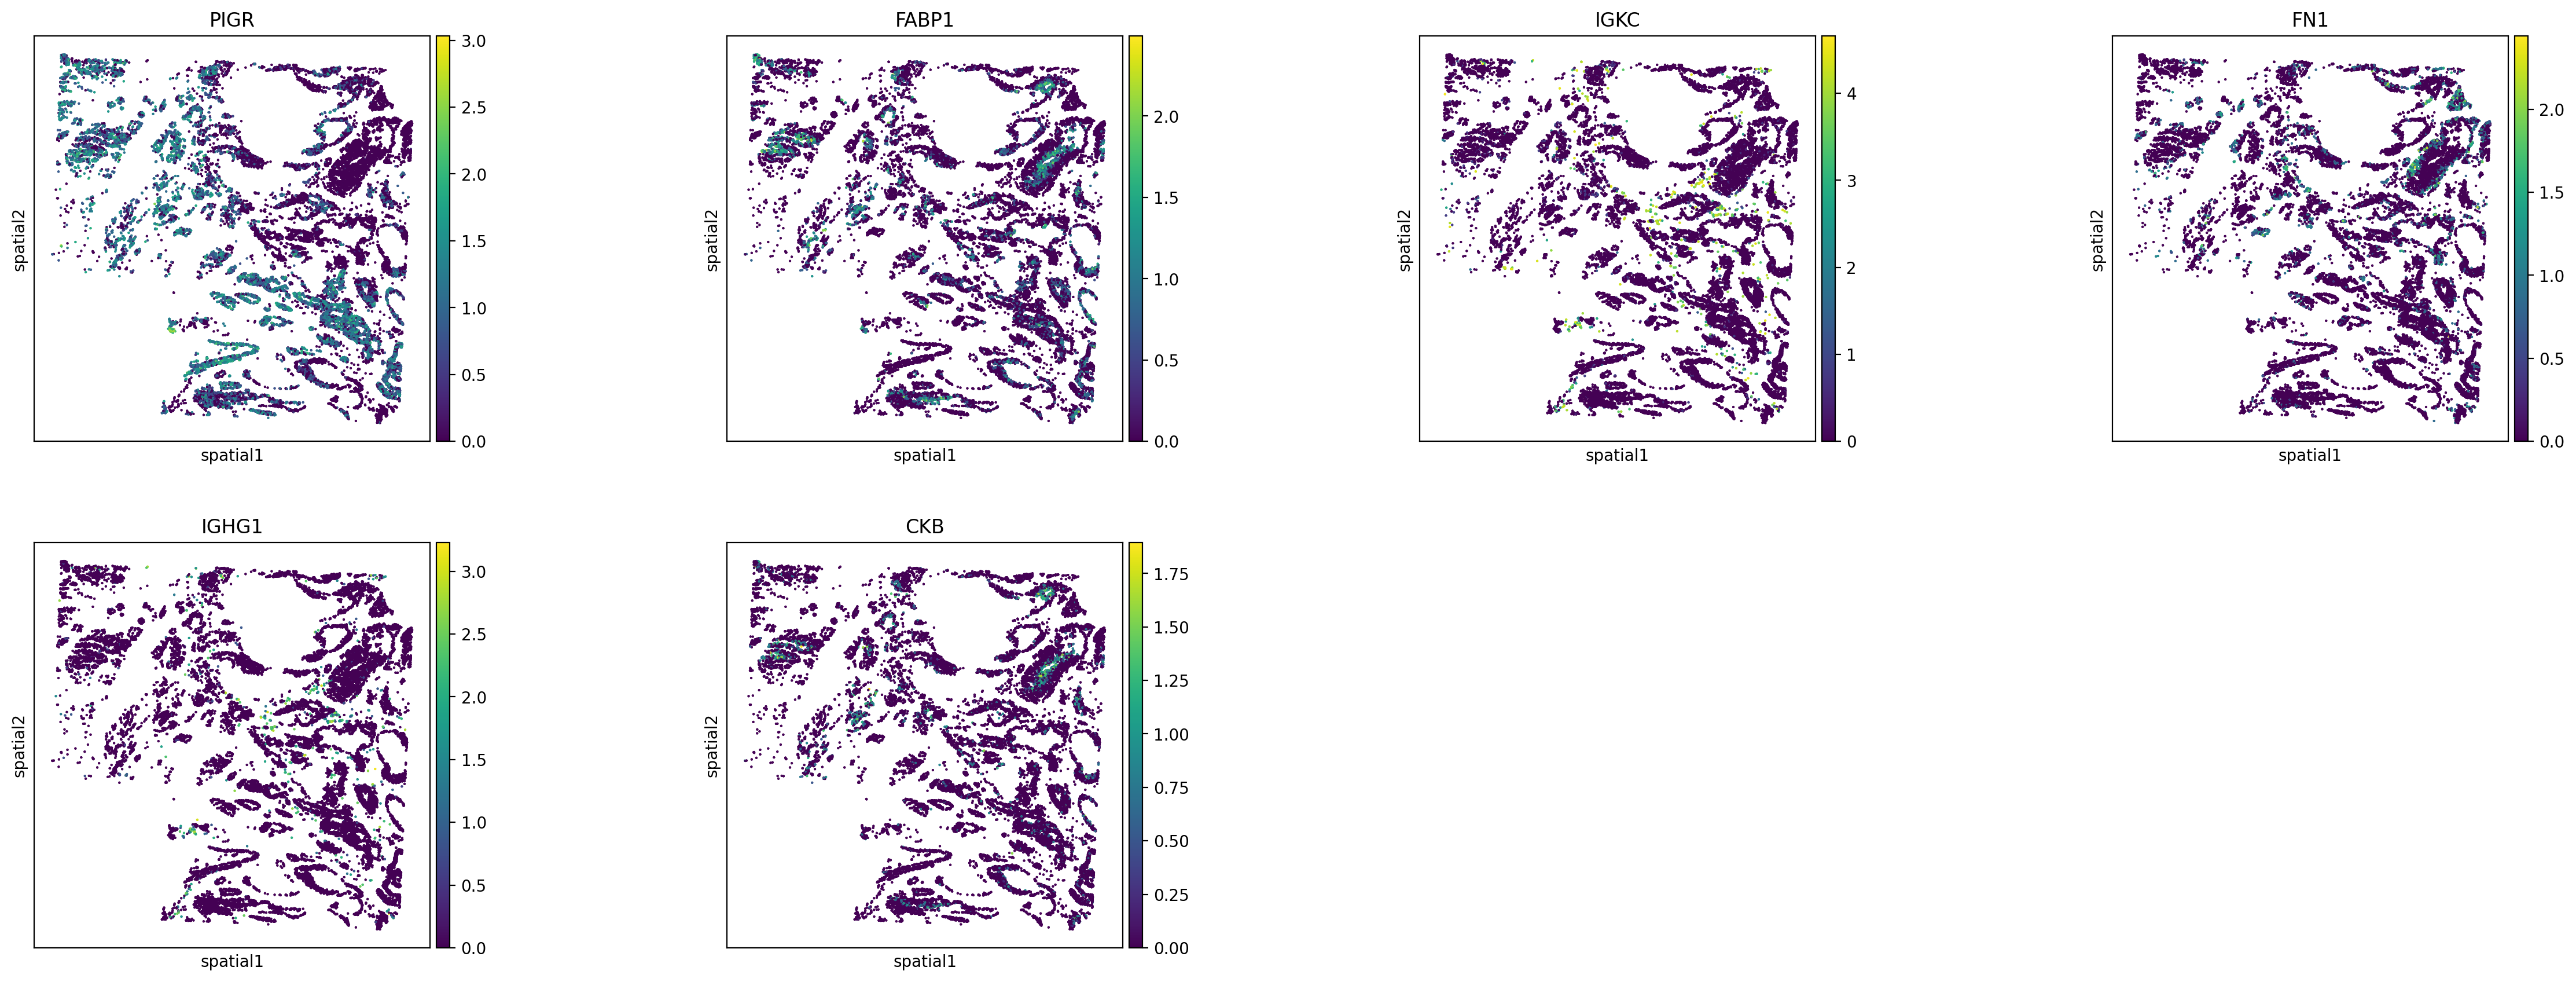

In [20]:
# count_area_filtered_adata = sc.read_h5ad(dir_custom_binning / "count_area_filtered_adata.h5ad")

top_svgs = count_area_filtered_adata.uns['moranI'].sort_values('I', ascending=False).head(6).index.tolist()

sq.pl.spatial_scatter(
    count_area_filtered_adata,
    color=top_svgs,
    shape=None,
    size=1,
)

## Merging the output
This step should be done after custom binning has been done for all samples.  
**Please make sure that only folders created by the cell segmentation/custom binning (equaling the samples) can be found in the corresponding output directory.**
This naming should also be consistent with the slide names and other instances where these names were used (e.g. patch creation).

Note: also be aware that currently the function does not assume any other parquet files other than the nuclei polygons. 


In [ ]:
import sys
import anndata as ad
import geopandas as gpd
import numpy as np
import pandas as pd
from pathlib import Path
import scanpy as sc

sys.path.insert(0, str(Path("../..").resolve()))
from functions.merge import merge_anndatas, merge_parquet

bin_size = "002um"
basedir = Path("../../data")
dir_custom_binning = "{basedir}/{sample}/01_preprocessing/cell_seg_stardist/{bin_size}/custom_binning"
path_template_custom_binning = dir_custom_binning + "/{filename}"

print([p.name for p in basedir.iterdir() if (p.is_dir())])

# Reference-only columns that are identical across samples and don't need per-sample preservation
# (safe to leave to merge="first" since they describe the gene itself, not sample-derived statistics)
REFERENCE_ONLY_VAR_COLS = {'gene_ids', 'feature_types', 'genome'}


In [2]:
exclude_dirs = ["new"] # exclude any data directories that are not supposed to be merged -> see print statemetn above
samples = [p.name for p in Path(basedir).iterdir() if (p.is_dir() and (p.name != "combined") and p.name not in exclude_dirs)]
print("Samples to merge: ", samples)

Samples to merge:  ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']


In [ ]:
# merge_anndatas / merge_parquet now live in functions/merge.py (shared with
# merge_patch_embeddings in 02_downstream_analysis_uni.ipynb, which used to be
# a near-duplicate of this cell) -- imported above.


In [ ]:
# Basic merging of the files
print("merging nuclei")
merged_nuclei_grouped_UMI_count = merge_anndatas(
    samples, path_template_custom_binning, "nuclei_grouped_UMI_count.h5ad", basedir,
    auto_detect_var_cols=True, reference_only_var_cols=REFERENCE_ONLY_VAR_COLS, bin_size=bin_size,
)

print("merging custom bins")
merged_custom_bins = merge_anndatas(
    samples, path_template_custom_binning, "filtered_custom_bins.h5ad", basedir,
    auto_detect_var_cols=True, reference_only_var_cols=REFERENCE_ONLY_VAR_COLS, bin_size=bin_size,
)

print("merging count area")
merged_count_area_filtered_adata = merge_anndatas(
    samples, path_template_custom_binning, "count_area_filtered_adata.h5ad", basedir,
    auto_detect_var_cols=True, reference_only_var_cols=REFERENCE_ONLY_VAR_COLS, bin_size=bin_size,
    per_sample_uns_moran_key="moranI",
)

print("merging geometry")
parquet_nuclei_geometry_list = merge_parquet(
    samples, path_template_custom_binning, "nuclei_geometry.parquet", basedir, bin_size=bin_size,
)


In [ ]:
# Recalculating global SVG, HVG, PCA and more

# --- Build cohort-level .var summary columns from the per-sample varm matrices ---
    # (var['highly_variable'] / var['spatially_variable'] straight off merge="first" would just
    # be one arbitrary sample's values -- rebuild them here as an explicit union across samples.)
hvg_per_sample = np.nan_to_num(
    merged_count_area_filtered_adata.varm['highly_variable_per_sample'], nan=0.0
).astype(bool)
merged_count_area_filtered_adata.var['highly_variable'] = hvg_per_sample.any(axis=1)
merged_count_area_filtered_adata.var['highly_variable_n_samples'] = hvg_per_sample.sum(axis=1)

I_THRESH = 0.1
FDR_THRESH = 0.05
moranI = merged_count_area_filtered_adata.varm['moranI_per_sample']
moranI_pval = merged_count_area_filtered_adata.varm['moranI_pval_per_sample']
svg_per_sample = (moranI_pval < FDR_THRESH) & (moranI > I_THRESH)
svg_per_sample = np.nan_to_num(svg_per_sample, nan=0.0).astype(bool)
merged_count_area_filtered_adata.var['spatially_variable'] = svg_per_sample.any(axis=1)
merged_count_area_filtered_adata.var['spatially_variable_n_samples'] = svg_per_sample.sum(axis=1)

# batch aware recompuation of global hvg 
sc.pp.highly_variable_genes(
    merged_count_area_filtered_adata,
    flavor="seurat",
    n_top_genes=2000,
    batch_key="Slide_ID",
)

# PCA based on batch-aware HVGs
sc.pp.pca(merged_count_area_filtered_adata, use_highly_variable=True)

merged_count_area_filtered_adata.var['gene_selection'] = 'none'
merged_count_area_filtered_adata.var.loc[
    merged_count_area_filtered_adata.var['highly_variable'], 'gene_selection'
] = 'HVG'
merged_count_area_filtered_adata.var.loc[
    merged_count_area_filtered_adata.var['spatially_variable'], 'gene_selection'
] = 'SVG'
merged_count_area_filtered_adata.var.loc[
    merged_count_area_filtered_adata.var['highly_variable']
    & merged_count_area_filtered_adata.var['spatially_variable'],
    'gene_selection'
] = 'HVG_and_SVG'

print(merged_count_area_filtered_adata.var['gene_selection'].value_counts())
print("TOTAL SVG union count: ", merged_count_area_filtered_adata.var['spatially_variable'].sum())  # 365

gene_selection
none           13407
HVG             4313
HVG_and_SVG      235
SVG              130
Name: count, dtype: int64


In [16]:
# print SVG count per sample
for i, sid in enumerate(merged_count_area_filtered_adata.uns['sample_order']):
    n_pass = ((moranI_pval[:, i] < 0.05) & (moranI[:, i] > 0.1)).sum()
    print(sid, n_pass)

CRC_P1 143
CRC_P2 183
CRC_P5 166
Normal_P3 232
Normal_P5 141


In [21]:
merged_count_area_filtered_adata

AnnData object with n_obs × n_vars = 456881 × 18085
    obs: 'id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'clusters', 'Slide_ID'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'moranI', 'moranI_pval_fdr', 'spatially_variable', 'highly_variable_n_samples', 'spatially_variable_n_samples', 'gene_selection', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'sample_order', 'pca_loadings_per_sample', 'pca_variance_ratio_per_sample', 'hvg', 'pca'
    obsm: 'spatial', 'X_pca_per_sample_raw', 'X_pca'
    varm: 'dispersions_per_sample', 'dispersions_norm_per_sample', 'highly_variable_per_sample', 'log1p_mean_counts_per_sample', '

# Assigning bins/nuclei to patches

**Loading the data**  
As a last step for preprocessing, we want to assign bins to the matching uni-patches. 
For this, we use the following functions:

In [1]:
import geopandas as gpd
from pathlib import Path
import scanpy as sc
from shapely.geometry import box

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
# Variables
sample = "combined"
bin_size = "002um"
patch_size = 224
cellseg_dir = "cell_seg_stardist"

# Paths
basedir = Path("../../data")
dir_trans = basedir / sample / "01_preprocessing" / cellseg_dir / bin_size / "custom_binning"
dir_histology = basedir / sample / "01_preprocessing/unimodel/metadata"

# Filenames
f_filtered_bins = "filtered_custom_bins.h5ad"
f_patch_embeddings = "filtered_WSI_patch_embeddings.h5ad"
f_nuclei_adata = "count_area_filtered_adata.h5ad"
f_nuclei_geometry = "nuclei_geometry.parquet"

- `adata_patches`: AnnData file containing patch embeddings for each patch, identified by index `SlideID_PatchID`. Also contains both Slide_ID and Patch_ID as separate columns
- `nuclei_geometry`: parquet file loaded as a geopandas data frame. Contains the polygons for each nucleus, which are identified by the nucleus ID and the Slide ID, if there is more than one slide.
- `nuclei_adata`: AnnData File containing embeddings and more for each (filtered) nucleus from each slide. Indexed by Slide_ID and nucleus_ID.


Since we already have geometries for nuclei and positions for patches, we will use spatial joins from GeoPandas.

In [3]:
## Loading files
# UNI model
adata_patches = sc.read_h5ad(dir_histology / f_patch_embeddings)

# Nuclei information
nuclei_geometry = gpd.read_parquet(dir_trans / f_nuclei_geometry)
nuclei_adata = sc.read_h5ad(dir_trans / f_nuclei_adata)

# merge nuclei positions with adata_filtered_nuclei
nuclei_adata.obs = nuclei_adata.obs.merge(nuclei_geometry, on=["Slide_ID", "id"], how="left")

**Assigning Transcriptomics Info to Patches**  
In this section we aim to combine transcriptomics and histology by determining which nucleus polygon or bin should be assigned to which patch.
For this we create a polygon for each patch and then load the polygons for each nucleus/bin.
We then determine the overlap.
Currently, we assign each nucleus to exactly one patch by choosing the largest overlapping portion (percent wise). 
Optionally, the user can also decide to return a dataframe containing the overlapping percentages for a nucleus for each patch in Step 3 in the function `assign_cells_to_patches`.

**Assigning Cells to Patches**  
The functions below maps cells to patches. 
- `def assign_cells_to_patches`: This functions takes both the histology and the transcriptomics data to calculate an overlap of the nuclei with the patches from each slide. 
For this, a polygon for each patch is created aand then an overlap is calculated for each nucleus polygon to determine overlap percentage with possible patch polygons. 
We either return a dict that has the structure Slide_ID: {nucleus_ID: assigned patch_ID} or (if overlap percentage is desired) a panads dataframe containing the nucleus ID, the patches with overlay and the calculated overlay percentage per patch. 
- `def get_patch_for_cell`: Takes the required Slide_ID and Nucleus_ID from the `adata_filtered_nuclei` and returns the assigned patch from the dictionary. 
This information is later added to the `adata_filtered_nuclei.obs` in a new column called `Patch_ID`.
The AnnData object is then stored in a new file called `patch_assigned_count_area_filtered_adata.h5ad`, in the same folder as the original anndata object. 


In [4]:
# Functions for assining cells to patches and adding the Patch IDs back to the adata_filtered_nuclei.
# Function to assign cells to patches based on maximum overlap. Per individual slide/sample. 
# hist_data: Histology AnnData (see uni model). ID: slideID_patchID, patches with embeddings, contain Slide_ID (i.e. sample) and top left pixel corner (X, Y)
# trans_data = Transcriptomics. ID: nucleus_ID ("ID"), contains (among others) geometry (polygon of nucleus in pixels)
# slide_id = sample
# box_size = set to patch_size
def assign_cells_to_patches_2(hist_data, trans_data, slide_id, box_size=224, sample=None):

    print(f"Working on single slide: {slide_id}")
    core_data_hist = hist_data[hist_data['Slide_ID'] == slide_id]
    if core_data_hist.empty:
        print(f"No box data for {slide_id}")
        return {}


    patch_geometries = [
        box(row['X'], row['Y'], row['X'] + box_size, row['Y'] + box_size)
        for _, row in core_data_hist.iterrows()
    ]
    patches_gdf = gpd.GeoDataFrame(core_data_hist[['Patch_ID']], geometry=patch_geometries, crs=None)
    patches_gdf['patch_index'] = patches_gdf.index  # in case match_id is not unique

    # turn trans_data into gdf for polygon operations
    trans_data = trans_data[trans_data.obs["Slide_ID"] == slide_id] 
    
    transcr_gdf = gpd.GeoDataFrame(
        trans_data.obs.reset_index(drop=True), 
        geometry=trans_data.obs.reset_index(drop=True)["geometry"],
        crs=None
    )

    print(f"Transcriptomics bounds for {sample}:", transcr_gdf.total_bounds)  # minx, miny, maxx, maxy of nuclei
    print(f"Histology bounds for {sample}:", patches_gdf.total_bounds)

    # composite id since nucleus id is not unique over mutiple samples
    transcr_gdf['composite_id'] = transcr_gdf['Slide_ID'].astype(str) + "_" + transcr_gdf['id'].astype(str)

    overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')
    overlaps['intersection_area'] = overlaps.geometry.area
    overlaps['cell_area'] = overlaps.groupby('composite_id')['intersection_area'].transform('sum')
    overlaps['percent_covered'] = overlaps['intersection_area'] / overlaps['cell_area']

    best_matches = overlaps.sort_values('percent_covered', ascending=False).drop_duplicates(subset='composite_id')

    # best_matches['id']=sample + "_" + best_matches['id'].astype(str)
    best_matches['id']=best_matches['id'].astype(str)
    
    # check unique matches
    n_unique = best_matches["id"].unique()
    n_non_unique = best_matches["id"].count() - len(n_unique)
    if n_non_unique > 0:
        print(f"Warning: {n_non_unique} nuclei have been assigned to multiple patches for {slide_id}.")
    
    cell_to_patch = dict(zip(best_matches['id'], best_matches['Patch_ID']))

    # return pd.DataFrame(best_matches[['id', 'Patch_ID', 'percent_covered']])
    return cell_to_patch # or pd.DataFrame(best_matches[['index', 'match_id', 'percent_covered']])

def assign_cells_to_patches(hist_data, trans_data, slide_id, box_size=224, sample=None):
    """
    Assigns cells/nuclei to histology patches based on maximum spatial overlap.
    Safely handles non-unique cell IDs across different slides by building temporary 
    composite keys.
    """
    print(f"Working on single slide: {slide_id}")
    
    # 1. Subset histology data to current slide and build patch geometries
    core_data_hist = hist_data[hist_data['Slide_ID'] == slide_id]
    if core_data_hist.empty:
        print(f"No box data for {slide_id}")
        return {}

    patch_geometries = [
        box(row['X'], row['Y'], row['X'] + box_size, row['Y'] + box_size)
        for _, row in core_data_hist.iterrows()
    ]
    patches_gdf = gpd.GeoDataFrame(core_data_hist[['Patch_ID']], geometry=patch_geometries, crs=None)
    patches_gdf['patch_index'] = patches_gdf.index  

    # 2. Subset transcriptomics to current slide and convert to GeoDataFrame
    trans_data_subset = trans_data[trans_data.obs["Slide_ID"] == slide_id] 
    
    transcr_gdf = gpd.GeoDataFrame(
        trans_data_subset.obs.reset_index(drop=True), 
        geometry=trans_data_subset.obs.reset_index(drop=True)["geometry"],
        crs=None
    )

    print(f"Transcriptomics bounds for {sample}:", transcr_gdf.total_bounds)  
    print(f"Histology bounds for {sample}:", patches_gdf.total_bounds)

    # 3. Create a unique composite key to bulletproof the groupby operations
    transcr_gdf['composite_id'] = transcr_gdf['Slide_ID'].astype(str) + "_" + transcr_gdf['id'].astype(str)

    # 4. Compute spatial intersection
    overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')
    
    if overlaps.empty:
        print(f"Warning: No spatial overlaps found between nuclei and patches for {slide_id}.")
        return {}
 
    # 5. Calculate area percentages using the composite ID
    overlaps['intersection_area'] = overlaps.geometry.area
    overlaps['cell_area'] = overlaps.groupby('composite_id')['intersection_area'].transform('sum')
    overlaps['percent_covered'] = overlaps['intersection_area'] / overlaps['cell_area']

    # 6. Keep only the patch with the maximum coverage per nucleus
    best_matches = overlaps.sort_values('percent_covered', ascending=False).drop_duplicates(subset='composite_id')

    # Convert ID column explicitly to string to match mapping requirements
    best_matches['id'] = best_matches['id'].astype(str)
    
    # 7. Check for anomalies
    n_unique = best_matches["id"].unique()
    n_non_unique = best_matches["id"].count() - len(n_unique)
    if n_non_unique > 0:
        print(f"Warning: {n_non_unique} nuclei have duplicate matches after filtering for {slide_id}.")
    
    # 8. Build dictionary mapping original nucleus 'id' -> 'Patch_ID'
    cell_to_patch = dict(zip(best_matches['id'], best_matches['Patch_ID']))

    return cell_to_patch

def get_patch_for_cell(row, all_mappings):
    slide = row["Slide_ID"]
    nucleus_id = str(row["id"])
    return all_mappings.get(slide, {}).get(nucleus_id, None)


In [5]:
all_mappings = {}

samples = nuclei_adata.obs["Slide_ID"].unique() 
available_samples = adata_patches.obs["Slide_ID"].unique() 

print("Samples in nuclei file: ", samples)
print("Samples with available segmented image patches: ", available_samples)

for sample in samples:
    print(f"Processing {sample}...")
    if sample not in available_samples:
        print(f"Skipping {sample} as no patches are available.")
        continue

    mapping = assign_cells_to_patches(adata_patches.obs, nuclei_adata, sample, 224, sample)
    all_mappings[sample] = mapping

#if not single_slide:
nuclei_adata.obs["Patch_ID"] = nuclei_adata.obs.apply(
    get_patch_for_cell, axis=1, args=(all_mappings,)
)
#else:
    #adata_filtered_nuclei.obs["Patch_ID"] = adata_filtered_nuclei.obs["id"].map(mapping)

Samples in nuclei file:  ['CRC_P1' 'CRC_P2' 'CRC_P5' 'Normal_P3' 'Normal_P5']
Samples with available segmented image patches:  ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
Categories (5, object): ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
Processing CRC_P1...
Working on single slide: CRC_P1
Transcriptomics bounds for CRC_P1: [  680.6541748  14102.36791992 24408.42016602 36828.15768433]
Histology bounds for CRC_P1: [  448. 12137. 24416. 36777.]
Processing CRC_P2...
Working on single slide: CRC_P2
Transcriptomics bounds for CRC_P2: [ 4.06127327e+04 -2.00238323e+00  6.51952937e+04  2.27043989e+04]
Histology bounds for CRC_P2: [40580.     0. 65220. 22624.]


/tmp/ipykernel_24335/2891210753.py:96: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')


Processing CRC_P5...
Working on single slide: CRC_P5
Transcriptomics bounds for CRC_P5: [44276.56304932 39505.73687744 65184.72583008 64026.39868164]
Histology bounds for CRC_P5: [44268. 39511. 68236. 63927.]


/tmp/ipykernel_24335/2891210753.py:96: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')


Processing Normal_P3...
Working on single slide: Normal_P3
Transcriptomics bounds for Normal_P3: [  477.24798584  9501.35229492 21763.56469727 34006.45556641]
Histology bounds for Normal_P3: [    0.  9496. 21728. 33912.]


/tmp/ipykernel_24335/2891210753.py:96: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')


Processing Normal_P5...
Working on single slide: Normal_P5
Transcriptomics bounds for Normal_P5: [41683.55029297 26473.67016602 66190.97558594 47305.55541992]
Histology bounds for Normal_P5: [41684. 26477. 66100. 50893.]


In [7]:
# Drop geometry again
# Save to new Anndata file (for now)
nuclei_adata.obs = nuclei_adata.obs.drop(columns=["geometry", "centroid", "interior_centroid"])
nuclei_adata.write(dir_trans / f_nuclei_adata)